# demo for facedetection with ImageProcessor

In [1]:
import os
from pathlib import Path

from dotenv import load_dotenv
from cv_utils import ImageProcessor, display, display_grid

import cv2

print("cv2 verison", cv2.__version__)

cv2 verison 4.8.0


### set data Paths

In [2]:
load_dotenv()

PROJECT_ROOT = Path(os.getenv("PROJECT_ROOT"))
DATA_DIR = Path(os.getenv("DATA_DIR"))

image_path = DATA_DIR / "ai-faces-1.jpg"
xml_path = Path(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")

print("Datadir is dir    :", DATA_DIR.is_dir())
print("Image Path exists :", image_path.exists())
print("xml_path exists   :", xml_path.exists())

Datadir is dir    : True
Image Path exists : True
xml_path exists   : True


## Create and Inject Cascade Pipeline to ImageProcessor

and explore bellow...

In [3]:
from cv_utils.detection import CascadeDetectionPipeline

drawing_params={
    'color': (255, 0, 0),
    'thickness': 3,
    'text_color': (0, 0, 255),
    'font_scale': 2.0,
}

pipeline = CascadeDetectionPipeline(
    xml_path=xml_path,
    drawing_params=drawing_params,
)

cascade_processor = ImageProcessor(
    img_src=image_path,
    pipeline=pipeline,
)

Will save on file size but feel free to explore these bellow.
We have methods for -> (np.ndarray):
- bgr_2_gray()
- bgr_2_rgb()
- bgr_2_hsv()

we have also methods that just loads and shows from path - no return.
- cascade_processor.show()
- show_bgr_gs_hsv_rgb()

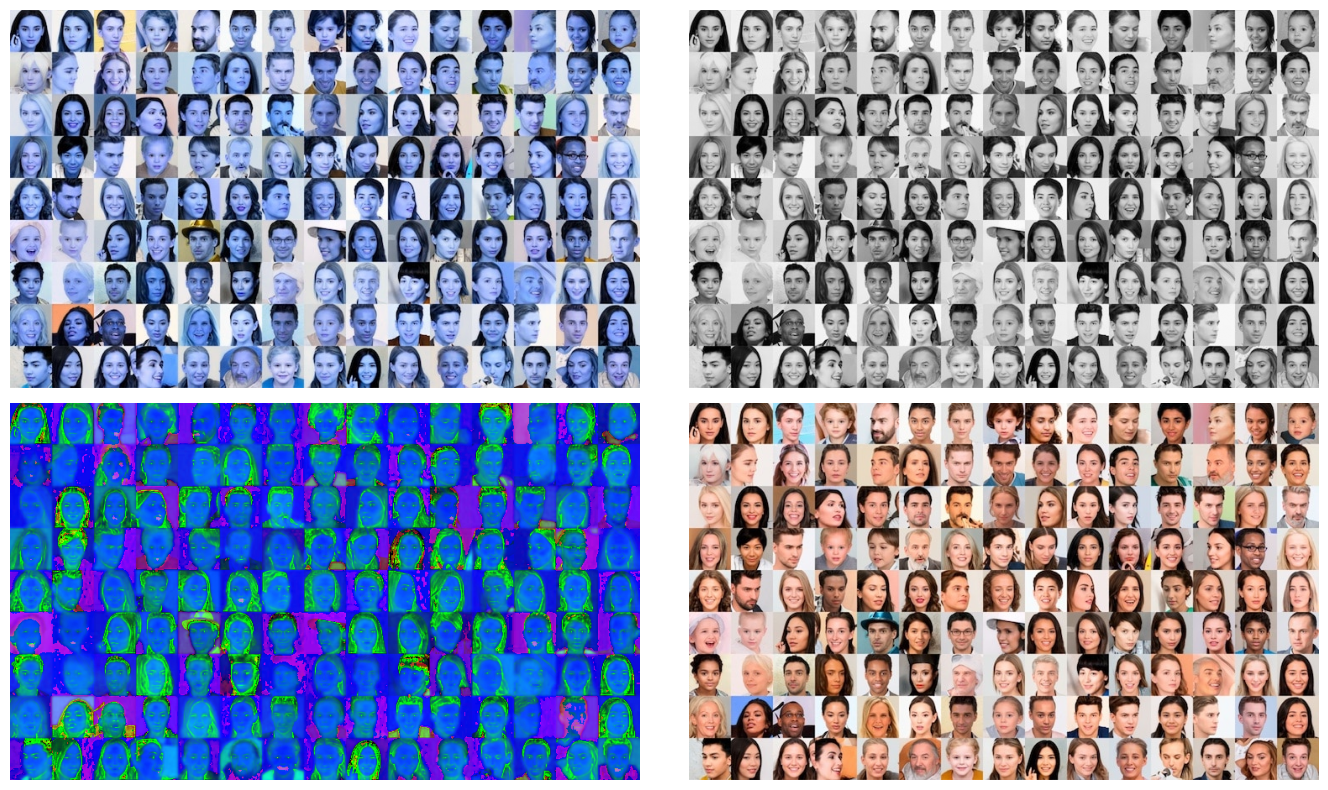

In [4]:
cascade_processor.show_bgr_gs_hsv_rgb()

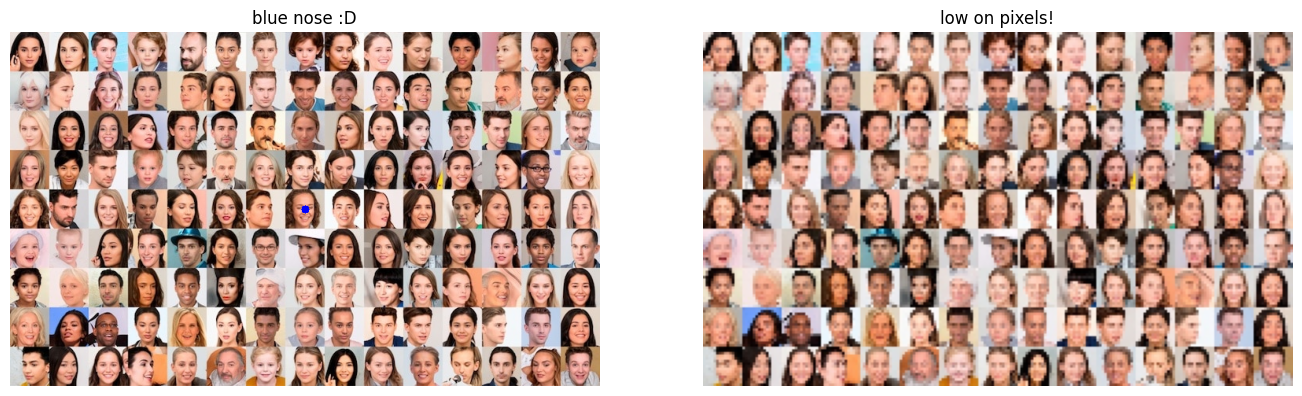

In [5]:
# center_img is not stored in class
display_grid(
    [
        cascade_processor.find_center(),
        cascade_processor.resize_to_rgb(scale=0.3)
    ],
    titles=["blue nose :D", "low on pixels!"])

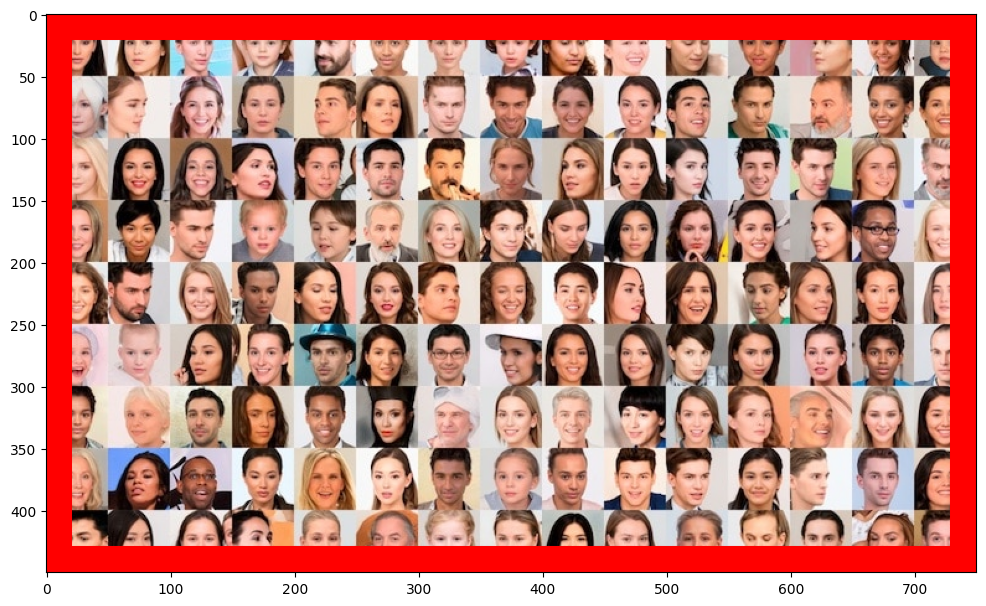

In [6]:
#TODO: adjust image scale, so the frame does not overwrite any information

out_path = DATA_DIR / "red_frame.png"

frame_it = cascade_processor.frame_it(
    color=(255, 0, 0),              # = (255, 0, 0)
    thickness=20,                   # = 20
    output_path=out_path,           # :str|Path|None = None (no output)
)
display(frame_it)

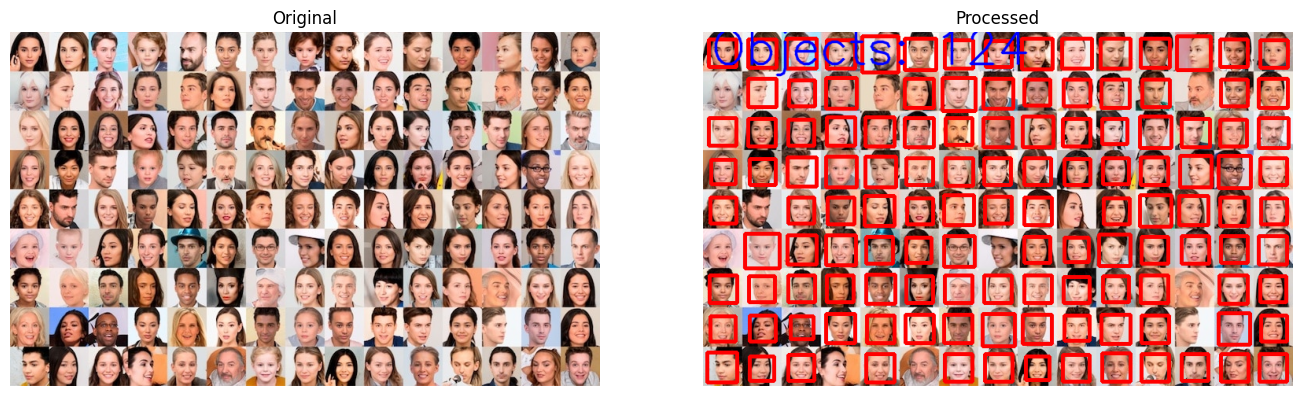

In [7]:
# An optional counter can be displayed in the image

processing_result = cascade_processor.process()

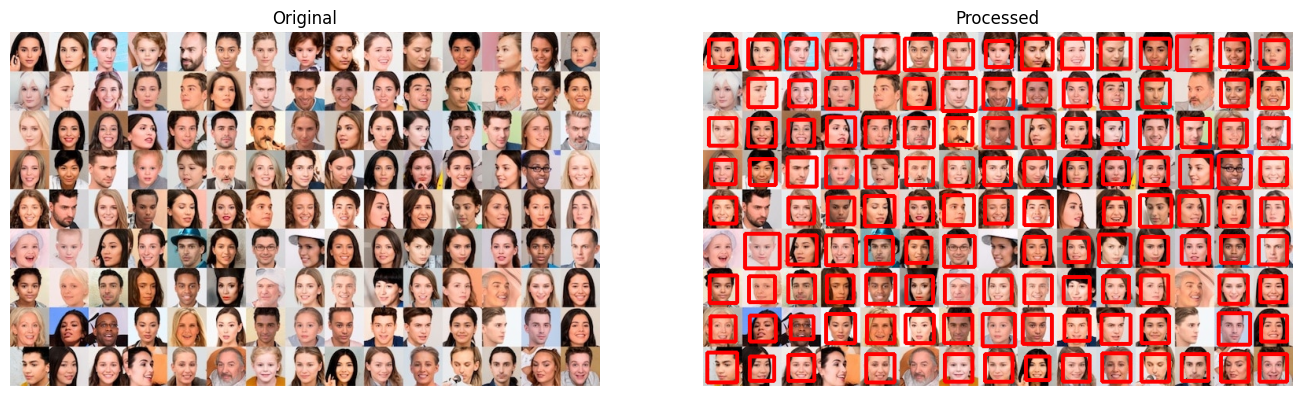

In [8]:
cascade_processor.pipeline.show_count = False
processing_result = cascade_processor.process()

In [9]:
print(cascade_processor)

IMAGE PROCESSOR

--- System ---
OS: Linux | | Python: 3.10.8 | OpenCV: 4.8.0

--- Image Settings ---
Source: ai-faces-1.jpg
Path: /home/dyretna/Dokument/Code/applied_ai_data

--- Pipeline ---
--- Cascade Detection ---
Cascade: haarcascade_frontalface_default.xml
Scale factor: 1.1
Min neighbors: 5
Min size: None
Max size: None

--- Detection Status ---
Last result: 124 object(s) detected

--- Visualization ---
Show count on image: No
Box color: (255, 0, 0)
Box thickness: 3



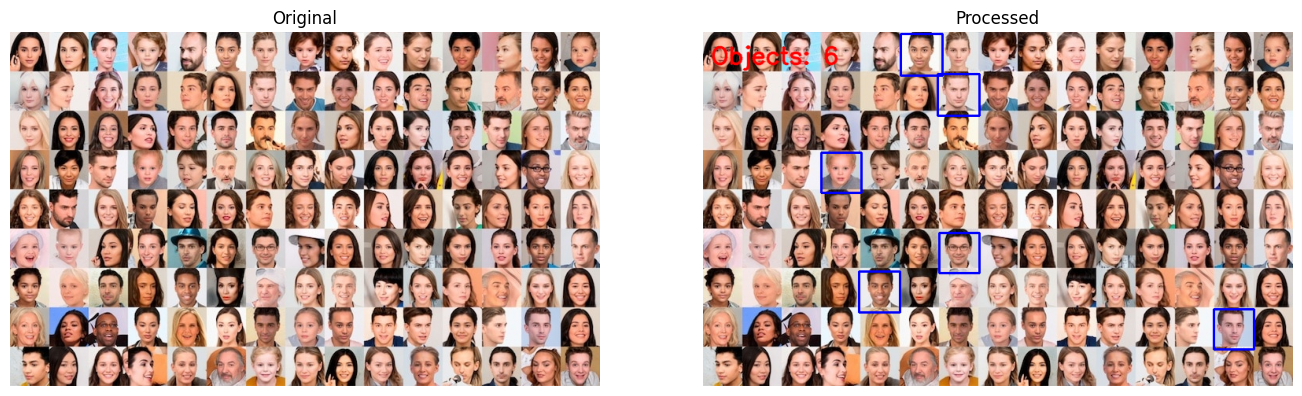

In [10]:
# show count is hard to access - initialized in constructor.
# since i want to have modular pipelines in the ImageProcessor,
# And the image proessor is the displayer,
# we would need a better interface.

# Is there a way to access pipeline parameter after init / in runtime?
# It does not feel clean to access pipeline-properties.

# -> pipelines should have a classmethod to create a new instance from the
# new parameters we want to pass. new parameters will merge with present.
# check to_pipeline() doc

kwargs = {
    "show_count": True,
    "drawing_params" : {
        'color'         : (0, 0, 255),
        'thickness'     : 2,
        'text_color'    : (255, 0, 0),
        'font_scale'    : 1.0,
    },
    # small faces
    "cascade_kwargs": {
        "scale_factor"  : 1.1,          # = 1.1
        "min_neighbors" : 5,            # = 5
        "min_size"      : (50, 50),     # = None
        "max_size"      : (60, 60),     # = None
    },
}

cascade_processor.to_pipeline(new_config=kwargs)
result = cascade_processor.process()

In [11]:
# we can also access metadata - its a contract as property for all pipelines
# not sure if its good praxis that the Image or Video processor is accessing it,
# but the contract makes it less coupled i guess...

# Video processors must have fast access to the metadata
# (only write frame when detecting)

cascade_processor.metadata.get("count", "N/A")

6

In [12]:
cascade_processor.metadata.get("detections", "N/A")[0]

array([300, 255,  51,  51], dtype=int32)

In [13]:
print(cascade_processor)

IMAGE PROCESSOR

--- System ---
OS: Linux | | Python: 3.10.8 | OpenCV: 4.8.0

--- Image Settings ---
Source: ai-faces-1.jpg
Path: /home/dyretna/Dokument/Code/applied_ai_data

--- Pipeline ---
--- Cascade Detection ---
Cascade: haarcascade_frontalface_default.xml
Scale factor: 1.1
Min neighbors: 5
Min size: 50x50
Max size: 60x60

--- Detection Status ---
Last result: 6 object(s) detected

--- Visualization ---
Show count on image: Yes
Box color: (0, 0, 255)
Box thickness: 2



# test with catfaces!

Same function as detect_faces  
The only thing that is changed is the xml file for `CascadeClassifier`

In [14]:
from pathlib import Path

haarcascades_dir = Path(cv2.data.haarcascades)
haarcascades_dir.is_dir()

True

In [15]:
for xml in haarcascades_dir.glob(pattern="*.xml"):
    print(xml)

/home/dyretna/Dokument/Code/GitHub/opencv-demos-py/.venv/lib/python3.10/site-packages/cv2/data/haarcascade_frontalface_alt_tree.xml
/home/dyretna/Dokument/Code/GitHub/opencv-demos-py/.venv/lib/python3.10/site-packages/cv2/data/haarcascade_frontalcatface.xml
/home/dyretna/Dokument/Code/GitHub/opencv-demos-py/.venv/lib/python3.10/site-packages/cv2/data/haarcascade_license_plate_rus_16stages.xml
/home/dyretna/Dokument/Code/GitHub/opencv-demos-py/.venv/lib/python3.10/site-packages/cv2/data/haarcascade_eye_tree_eyeglasses.xml
/home/dyretna/Dokument/Code/GitHub/opencv-demos-py/.venv/lib/python3.10/site-packages/cv2/data/haarcascade_frontalface_alt.xml
/home/dyretna/Dokument/Code/GitHub/opencv-demos-py/.venv/lib/python3.10/site-packages/cv2/data/haarcascade_frontalface_alt2.xml
/home/dyretna/Dokument/Code/GitHub/opencv-demos-py/.venv/lib/python3.10/site-packages/cv2/data/haarcascade_lowerbody.xml
/home/dyretna/Dokument/Code/GitHub/opencv-demos-py/.venv/lib/python3.10/site-packages/cv2/data/ha

In [16]:
cat_faces_path = DATA_DIR.joinpath("cat_faces_01.jpg")
catman_path = DATA_DIR.joinpath("catman_morrowwind.jpg")
print(cat_faces_path.exists())
print(catman_path.exists())

# Setup cat face detection with XML file
xml_file = haarcascades_dir / "haarcascade_frontalcatface_extended.xml"

# Create pipeline
catface_pipeline = CascadeDetectionPipeline(
    xml_path=xml_file,
    min_neighbors=3,
    drawing_params={'color': (255, 0, 255), 'thickness': 2}
)

print(catface_pipeline)

True
True
--- Cascade Detection ---
Cascade: haarcascade_frontalcatface_extended.xml
Scale factor: 1.1
Min neighbors: 3
Min size: None
Max size: None

--- Detection Status ---
Last result: No objects detected

--- Visualization ---
Show count on image: Yes
Box color: (255, 0, 255)
Box thickness: 2



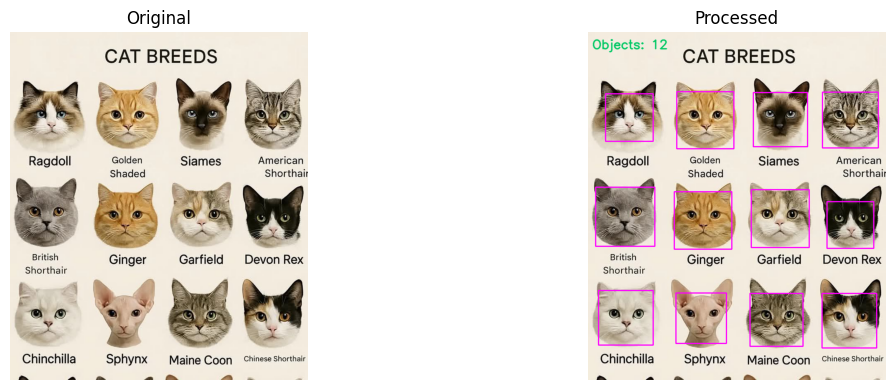

In [17]:
# Process cat_faces_01.jpg
processor = ImageProcessor(img_src=cat_faces_path, pipeline=catface_pipeline)
result = processor.process()

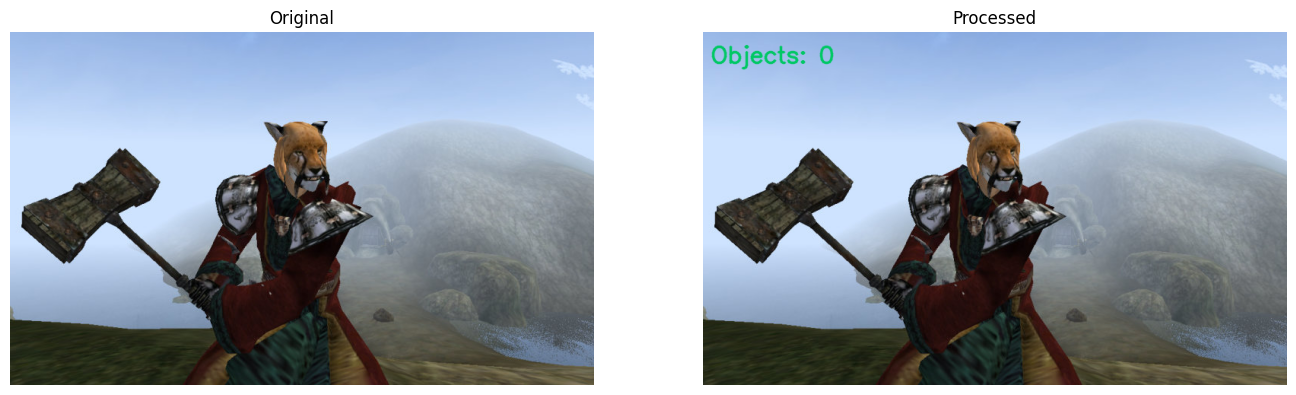

In [18]:
# Process catman_morrowwind.jpg
processor = ImageProcessor(img_src=catman_path, pipeline=catface_pipeline)
result = processor.process()

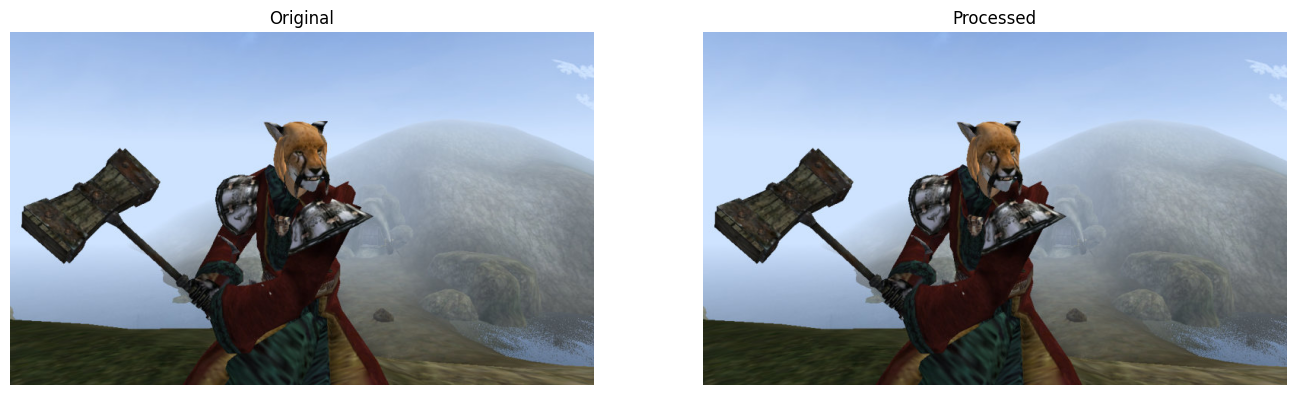

In [19]:
# Test human face detection on catman
# Setup cat face detection with XML file
xml_file = haarcascades_dir / "haarcascade_frontalface_alt2.xml"

# Create pipeline
humanface_pipeline = CascadeDetectionPipeline(
    xml_path=xml_file,
    min_neighbors=3,
    drawing_params={'color': (255, 0, 255), 'thickness': 2},
)
processor = ImageProcessor(img_src=catman_path, pipeline=pipeline)
result = processor.process()